# 02 · Model evaluation, explainability, fairness and drift

Loads the artefacts produced by `uv run credit-risk-train` (model + `reports/metrics.json`) and digs into *why* the model decides what it decides.

In [1]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_risk import plots
from credit_risk.config import load_config
from credit_risk.data import clean, load_raw, split

plots.apply_style()
pd.set_option("display.float_format", "{:.3f}".format)
cfg = load_config()
import json

from credit_risk.model import CreditRiskModel

model = CreditRiskModel.load(cfg.artifacts.model_path)
metrics = json.loads(cfg.artifacts.metrics_path.read_text())
df = clean(load_raw(cfg.data.raw_path))
train, valid, test = split(df, cfg.data.test_size, cfg.data.valid_size, cfg.seed)
print("model version", model.metadata["model_version"], "| threshold", model.threshold)

model version 1.0.0 | threshold 0.15


## 1 · Discrimination and calibration on the untouched test set

In [2]:
pd.DataFrame(metrics["test_metrics"]).T[["roc_auc", "gini", "ks", "pr_auc", "brier", "log_loss"]]

,roc_auc,gini,ks,pr_auc,brier,log_loss
logistic_regression,0.749,0.499,0.386,0.497,0.143,0.452
lightgbm_raw,0.782,0.563,0.428,0.563,0.135,0.428
lightgbm_final,0.782,0.563,0.428,0.563,0.135,0.428


In [3]:
pd.Series(metrics["calibration"]["cv_log_loss_validation"], name="CV log-loss (validation)")

none       0.430
sigmoid    0.430
isotonic   0.439
Name: CV log-loss (validation), dtype: float64

* LightGBM beats the logistic-regression baseline on every metric (ROC-AUC 0.78 vs 0.75, PR-AUC 0.56 vs 0.50, KS 0.43 vs 0.39).
* **Calibration was tested, not assumed.** The pipeline compared no calibration, Platt scaling and isotonic regression by cross-validated log-loss on the *validation* set. LightGBM trained with a log-loss objective was already well calibrated, so `none` won; isotonic regression would have made probabilities slightly *worse* (it over-fits a 4,800-row calibration set). That's why `lightgbm_raw` and `lightgbm_final` are identical above.

![calibration](../reports/figures/calibration.png)

## 2 · From probabilities to decisions

In [4]:
pd.DataFrame(metrics["decisions_test"]).T

,threshold,expected_cost,approval_rate,bad_rate_approved,defaulters_caught,goods_declined
approve_all,1.000,1.106,1.000,0.221,0.000,0.000
threshold_0.5,0.500,0.741,0.878,0.159,0.367,0.053
cost_optimal,0.150,0.559,0.495,0.093,0.793,0.423


With a missed defaulter assumed to cost 5× a wrongly declined good customer, the **cost-optimal threshold** declines far more applicants than the naive 0.5 cut-off and lowers expected cost per applicant substantially versus *approve everyone*. The cost ratio is a business input (`configs/train.yaml`); the curve below shows how sensitive the result is to the threshold.

![cost curve](../reports/figures/cost_curve.png)

## 3 · Explainability (SHAP)

Global view: which features drive predicted risk, and in which direction.

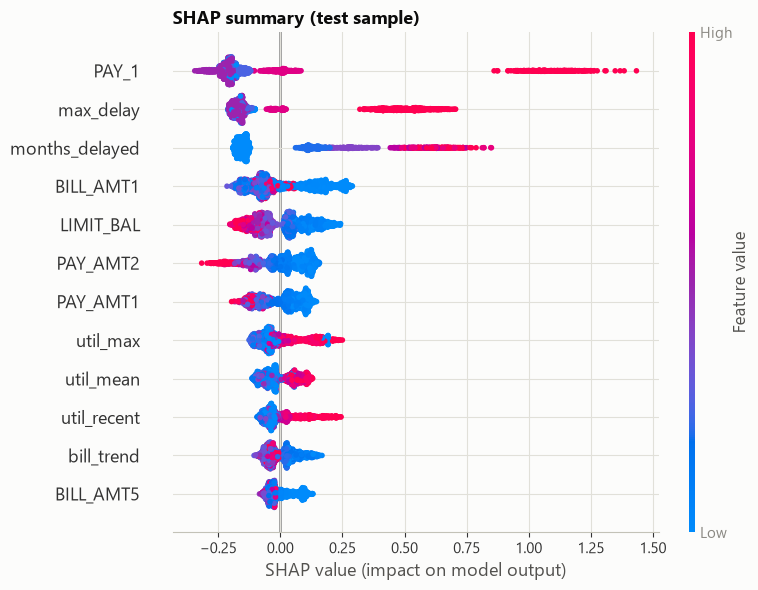

In [5]:
import shap

sample = test.sample(2000, random_state=0)
X = model.features(sample)
sv = model.contributions(sample)
shap.summary_plot(sv.to_numpy(), X, max_display=12, show=False, plot_size=(8, 6))
plt.title("SHAP summary (test sample)", loc="left")
plt.tight_layout()
plt.savefig("reports/figures/shap_summary.png", dpi=150)

Local view: the *reason codes* the API returns for a single high-risk applicant.

In [6]:
high = test.loc[[model.predict_pd(test).argmax()]]
print(
    "PD =",
    round(float(model.predict_pd(high)[0]), 3),
    "| decision =",
    model.decide(model.predict_pd(high))[0],
)
model.reason_codes(high, top_k=5)[0]

PD = 0.798 | decision = decline


[{'feature': 'PAY_1', 'contribution': 1.0491},
 {'feature': 'max_delay', 'contribution': 0.6037},
 {'feature': 'months_delayed', 'contribution': 0.5954},
 {'feature': 'bill_trend', 'contribution': 0.1359},
 {'feature': 'LIMIT_BAL', 'contribution': 0.1015}]

## 4 · Fairness audit

Protected attributes are not model inputs, but outcomes are compared across groups.

In [7]:
for name, rows in metrics["fairness_test"].items():
    print(f"\n{name}  (disparate impact ratio = {metrics['disparate_impact_ratio'][name]:.2f})")
    display(pd.DataFrame(rows).set_index("group"))


sex  (disparate impact ratio = 0.94)


,n,default_rate,approval_rate,tpr,fpr,auc
group,,,,,,
female,3598,0.213,0.506,0.792,0.413,0.786
male,2402,0.234,0.478,0.793,0.439,0.774



marriage  (disparate impact ratio = 0.79)


,n,default_rate,approval_rate,tpr,fpr,auc
group,,,,,,
married,2767,0.241,0.508,0.787,0.397,0.787
other,75,0.160,0.400,0.833,0.556,0.681
single,3158,0.205,0.486,0.797,0.441,0.780



age_band  (disparate impact ratio = 0.84)


,n,default_rate,approval_rate,tpr,fpr,auc
group,,,,,,
<30,1912,0.223,0.460,0.813,0.462,0.785
30-39,2198,0.206,0.532,0.788,0.385,0.789
40-49,1341,0.233,0.506,0.776,0.409,0.772
50+,549,0.246,0.446,0.785,0.478,0.768


**Reading the table.** The disparate impact ratio compares approval rates (min/max); the common *four-fifths rule* flags values below 0.8. The false positive rate (`fpr`) is the share of *good* customers wrongly declined, which is where unequal error burden shows up.

* **Sex:** the approval gap (0.94 ratio) is in line with the difference in observed default rates, and error rates are similar.
* **Age:** customers under 30 and over 50 are declined more often (FPR ≈ 0.46–0.48 vs 0.39 for 30–39). Credit limit and utilisation are likely proxies, since young customers tend to have lower limits.
* **Marital status:** the small *other* group (n = 75) falls below the four-fifths threshold (0.79) even though its observed default rate is the lowest. With only 75 customers this estimate is very noisy, but in production it would be **flagged for review**.

Possible mitigations are group-level threshold analysis, removing or constraining proxy features, and collecting more data for small groups. Each should go through a business and legal review.

![fairness](../reports/figures/fairness.png)

## 5 · Drift monitoring (PSI)

The training run stores a reference profile of every feature. In production, each new batch is compared against it. Below: (a) the real test set — should be stable; (b) a simulated *economic shock* where 30 % of customers slip one more month behind on payments.

In [8]:
from credit_risk.features import build_features
from credit_risk.monitoring import drift_report, load_profile

profile = load_profile(cfg.artifacts.reference_profile_path)
print("test set - max PSI:", round(drift_report(profile, build_features(test))["psi"].max(), 3))

rng = np.random.default_rng(0)
shock = test.copy()
hit = rng.random(len(shock)) < 0.30
for c in ["PAY_1", "PAY_2", "PAY_3"]:
    shock.loc[hit, c] = np.clip(shock.loc[hit, c].clip(lower=0) + 1, -2, 9)
report = drift_report(profile, build_features(shock))
report.head(8)

test set - max PSI: 0.003


,feature,psi,status
0,months_delayed,0.376,significant
1,max_delay,0.295,significant
2,PAY_1,0.252,significant
3,delay_trend,0.168,moderate
4,PAY_2,0.054,stable
5,PAY_3,0.049,stable
6,months_no_consumption,0.017,stable
7,util_mean,0.003,stable


In [9]:
base_pd = model.predict_pd(test).mean()
shock_pd = model.predict_pd(shock).mean()
print(f"mean predicted PD: {base_pd:.3f} -> {shock_pd:.3f}")
print(
    f"approval rate   : {(model.predict_pd(test) < model.threshold).mean():.1%} -> {(model.predict_pd(shock) < model.threshold).mean():.1%}"
)

mean predicted PD: 0.221 -> 0.264
approval rate   : 49.5% -> 36.2%


PSI flags the shifted delinquency features as *significant*, which would trigger an alert, an investigation and potentially a retraining job — while the model correctly reacts to the riskier population with higher PDs and fewer approvals.

## Limitations

* Data is from 2005 Taiwan; one snapshot, no time dimension → no out-of-time validation possible.
* Costs are illustrative; a real lender would use exposure-at-default and loss-given-default per account.
* Fairness audit is descriptive; it does not establish causation or legal compliance.